# The Lagrange invariant, the sine condition and the Herschel condition

A lens that forms a perfect image of one point has done only part of
its job. The image of a neighbouring point must be perfect too, and
whether it is depends on how the lens maps directions: it is a property
of the whole pencil, not of single rays. Three classical results say
what a lens must conserve:

- the **Lagrange invariant** (also called the Helmholtz or
  Smith–Helmholtz invariant) of paraxial optics,
  $H = n(\bar u y - u\bar y)$ for a marginal ray $(y, u)$ and a chief ray
  $(\bar y, \bar u)$; between conjugate planes it reads
  $n\,y\,u = n'\,y'\,u'$, field times aperture is conserved;
- **Abbe's sine condition** $n\,y\sin U = n'\,y'\sin U'$, the exact,
  finite aperture version for a small field: a lens that is stigmatic on
  the axis also images the neighbouring points of the object plane
  sharply (no coma) if and only if $\sin U'/\sin U$ is the same for all
  rays (*aplanatism*);
- **Herschel's condition** $n\,\delta z\sin^2(U/2) = n'\,\delta z'\sin^2(U'/2)$,
  the same statement for neighbouring points *along the axis*: the image
  stays sharp when the object moves in depth.

Notebook 83 treats the same invariant in its general form, the étendue:
the volume of phase space that a beam occupies, conserved by every
lossless system (Liouville). Étendue is the illumination engineer's view
(how much light gets through); the conditions here are the lens
designer's view (which points are imaged sharply). They meet in phase
space: the sine condition is what Liouville's theorem demands of a
stigmatic lens that is also free of coma. And both the sine and the
Herschel condition have a wave optical meaning: the sine condition maps
the angular spectrum of the object linearly onto that of the image, so
that a grating is imaged as a grating and the PSF does not change shape
in a small field (*isoplanatism*); the Herschel condition does the same
for the axial spatial frequencies, so that the 3D image of a 3D object
is a scaled copy. The two cannot hold together, except at the one
magnification $|m| = n/n'$, which is how remote focusing microscopes
refocus without aberrations.

The notebook checks all of this with real rays and waves:

1. the Lagrange invariant through Caldwell's 42 surface lithography lens,
   the space bandwidth product, and the Wigner function of a laser beam
   as its wave optical counterpart (the beam quality $M^2$),
2. the sine condition: Conrady's offence against the sine condition
   (OSC) for a paraboloid, an ellipsoid, a bending series of singlets,
   classical Cassegrain against Ritchey–Chrétien and the lithography
   lens; OSC against the traced coma and the coma Zernike; Abbe's own
   grating argument and the PSF over a small field,
3. the aplanatic points of a sphere: a stigmatic and aplanatic surface
   at any aperture, the front lens of every microscope objective,
4. the Herschel condition: moving the object in depth, the spherical
   aberration that results against a closed form,
5. why not both: the Ewald caps of the 3D transfer function, a symmetric
   pair of lenses that satisfies both conditions, and remote focusing,
6. phase space: the sine condition from Liouville's theorem, the
   tangential coma from the Jacobian of the ray map, and the pupil
   apodization that a lens's mapping law imposes on its high NA focus.

The new functions are `System.sine_condition()` (OSC, the sine and
Herschel defects along real rays) and `System.lagrange_invariants()`.
Lengths are in mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import telescopes as tl
from pyoptics import illumination as il
from pyoptics import raywave as rw
from pyoptics import propagators as prop
from pyoptics import sketch
from pyoptics.fft import FT, inv_FT
from pyoptics.utils import freq_grid

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
lam = 550e-6                                   # mm

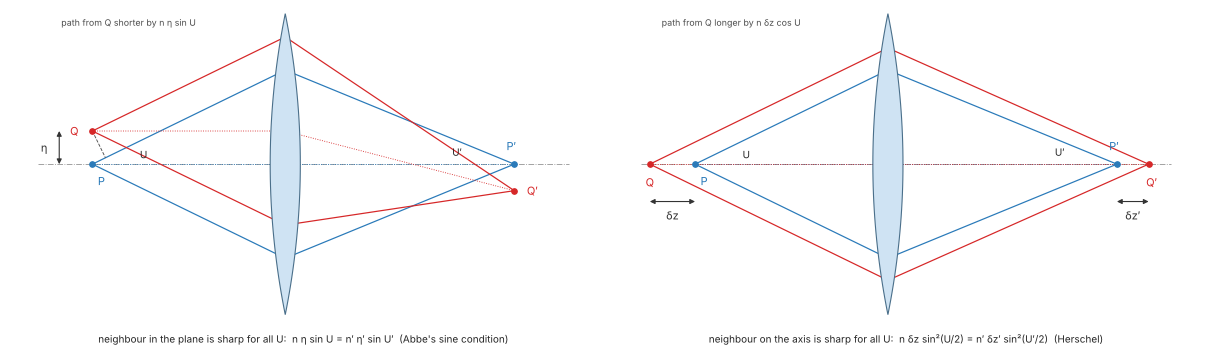

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
sketch.sine_herschel_conditions(ax[0], kind="sine")
sketch.sine_herschel_conditions(ax[1], kind="herschel")
plt.show()

## 1. One invariant, several names

Trace a paraxial marginal ray $(y, u)$ and a chief ray $(\bar y, \bar u)$
through a system. At every surface the reduced angles $nu$ change by
$-y\phi$ and $-\bar y\phi$ (the same power $\phi$), and in every gap the
heights change by $u\,t$ and $\bar u\,t$. Both steps leave

$$H = n(\bar u\,y - u\,\bar y)$$

unchanged: $H$ is the determinant of the matrix whose columns are the two
rays in reduced coordinates $(y, nu)$, and every ABCD matrix has
determinant 1 (notebook 08). Paraxial optics is a linear symplectic map
of the plane $(y, nu)$, and $H$ is the symplectic product of two rays.
In the object plane the chief ray has the height $\bar y = \eta$ and the
marginal ray $y = 0$, so $H = -n\,u\,\eta$; in the image plane
$H = -n'u'\eta'$. The **Helmholtz** (Smith–Helmholtz) form

$$n\,u\,\eta = n'\,u'\,\eta'$$

is the special case between conjugate planes, the **Lagrange** form holds
in any plane. They are the same invariant under two names; which one a
book uses depends mostly on the country it was written in.

Caldwell's KrF lithography lens (notebook 19) images a field of
46.8 mm radius 4× reduced at NA 0.536 in the image. $H$ behind each of
its 42 surfaces:

In [3]:
caldwell = rt.caldwell_krf_lens()
pc = caldwell.paraxial()
Hs = caldwell.lagrange_invariants()
print("Caldwell lens: H = {:.6f} mm, spread over the 42 surfaces {:.1e} mm (relative {:.1e})"
      .format(pc.lagrange, np.ptp(Hs), np.ptp(Hs)/abs(pc.lagrange)))
na_obj = abs(pc.na*pc.magnification)
eta_obj, eta_img = caldwell.max_field, abs(pc.image_height)
print("object: n u eta = {:.4f} x {:.3f} mm = {:.4f} mm; image: n' u' eta' = {:.4f} x {:.3f} mm = {:.4f} mm"
      .format(na_obj, eta_obj, na_obj*eta_obj, pc.na, eta_img, pc.na*eta_img))
G = (np.pi*pc.lagrange)**2
print("etendue pi^2 H^2 = {:.0f} mm^2, H/lambda = {:.0f}, modes G/lambda^2 = {:.2e}"
      .format(G, abs(pc.lagrange)/caldwell.wavelength, G/caldwell.wavelength**2))
print("Airy disks (radius 0.61 lambda/NA) in the image field: {:.2e}"
      .format((eta_img/(0.61*caldwell.wavelength/pc.na))**2))

Caldwell lens: H = -6.270187 mm, spread over the 42 surfaces 6.2e-15 mm (relative 9.9e-16)
object: n u eta = 0.1340 x 46.800 mm = 6.2702 mm; image: n' u' eta' = 0.5359 x 11.700 mm = 6.2702 mm
etendue pi^2 H^2 = 388 mm^2, H/lambda = 25252, modes G/lambda^2 = 6.29e+09
Airy disks (radius 0.61 lambda/NA) in the image field: 1.71e+09


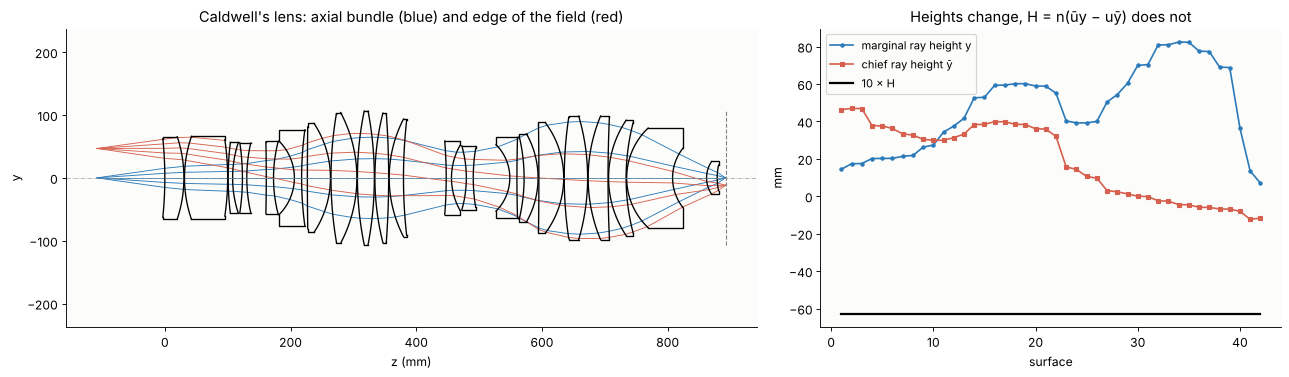

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained", width_ratios=[1.5, 1])
caldwell.draw(ax[0], n_rays=5, colors=[BLUE, RED])
ax[0].set_title("Caldwell's lens: axial bundle (blue) and edge of the field (red)")
ax[0].set_xlabel("z (mm)")
k = np.arange(1, len(Hs) + 1)
ax[1].plot(k, pc.marginal[:, 0], "o-", color=BLUE, ms=3, label="marginal ray height y")
ax[1].plot(k, pc.chief[:, 0], "s-", color=RED, ms=3, label="chief ray height ȳ")
ax[1].plot(k, Hs*10, "-", color="k", lw=2, label="10 × H")
ax[1].set_xlabel("surface")
ax[1].set_ylabel("mm")
ax[1].set_title("Heights change, H = n(ūy − uȳ) does not")
ax[1].legend(fontsize=10)
plt.show()

$H$ is constant to $10^{-15}$, while the two ray heights change by
factors of ten. In the object plane $n u \eta = 0.134 \times 46.8$ mm and
in the image $0.536 \times 11.7$ mm: the 4× smaller field comes with the
4× larger NA. $H$ also counts how much a lens can resolve. The
étendue of the field, $\pi^2 H^2$, divided by $\lambda^2$ is the number of
spatial modes (degrees of freedom) that the lens transmits, about
$6 \times 10^9$ here, and the number of Airy disks that fit into the image
field is of the same order ($1.7\times 10^{9}$). A lens designer who is
asked for more field *and* more NA is asked for a larger $H$, and every
lens in the system has to carry it: $H$ is a measure of how hard a lens
is to design (notebook 43 scales lenses at constant $H$).

### The wave optical Lagrange invariant: the Wigner function

A beam of light has an invariant of the same kind. Its Wigner function
$W(x, p)$ (notebook 47) is a wave optical density in the phase space of
position $x$ and direction $p = n\sin\theta$. A thin lens shears it in
$p$, free space shears it in $x$: every ABCD system moves $W$ like a
density of rays and keeps its area. The rms size of $W$,

$$\varepsilon = \sqrt{\langle x^2\rangle\langle p^2\rangle - \langle xp\rangle^2},$$

is then invariant too. It is the second moment form of $H$ (accelerator
physicists call it the rms emittance), and the uncertainty relation of
Fourier optics bounds it from below: $\varepsilon \ge \lambda/(4\pi)$,
with equality for a Gaussian TEM₀₀ beam, $w_0\theta_0 = \lambda/\pi$. A
beam of quality $M^2$ (notebook 07) has $\varepsilon = M^2\lambda/(4\pi)$:
$M^2$ is the Lagrange invariant of a laser beam in units of the smallest
possible one.

Aberrations are not ABCD maps. A lens with spherical aberration bends
the Wigner function into an S. Its true area stays (Liouville), but the
smallest ellipse that contains the S grows, and with it $M^2$:

TEM00 at its waist                         eps/(lambda/4pi) = M^2 = 1.0000
behind a thin lens, f = 20 mm              eps/(lambda/4pi) = M^2 = 1.0000
behind a lens with spherical aberration    eps/(lambda/4pi) = M^2 = 1.7555


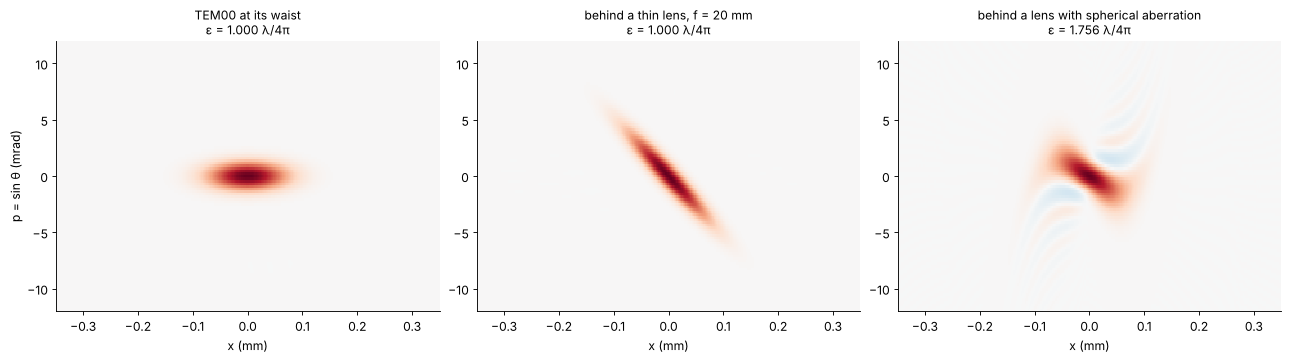

In [5]:
w0, f_lens = 0.1, 20.0
x = np.linspace(-0.6, 0.6, 512)
k0 = 2*np.pi/lam
u_in = np.exp(-(x/w0)**2)
lens_phase = -k0*x**2/(2*f_lens)                     # thin lens, exp(i k r ...) convention
sa_phase = 2*np.pi*3.0*(x/(2*w0))**4                 # 3 waves of spherical aberration at 2 w0
beams = {"TEM00 at its waist": u_in,
         "behind a thin lens, f = 20 mm": u_in*np.exp(1j*lens_phase),
         "behind a lens with spherical aberration": u_in*np.exp(1j*(lens_phase + sa_phase))}


def wigner_moments(u):
    kk, W = rw.wigner(u, x)
    p = kk/k0
    X, P = np.meshgrid(x, p)
    m = lambda a: np.sum(a*W)/np.sum(W)
    xc, pc_ = m(X), m(P)
    eps = np.sqrt(m((X - xc)**2)*m((P - pc_)**2) - m((X - xc)*(P - pc_))**2)
    return p, W, eps


fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), layout="constrained")
for a, (name, u) in zip(ax, beams.items()):
    p, W, eps = wigner_moments(u)
    a.pcolormesh(x, p*1e3, W/np.abs(W).max(), cmap="RdBu_r", vmin=-1, vmax=1, shading="auto",
                 rasterized=True)
    a.set_ylim(-12, 12)
    a.set_xlim(-0.35, 0.35)
    a.set_xlabel("x (mm)")
    a.set_title("{}\nε = {:.3f} λ/4π".format(name, eps/(lam/(4*np.pi))), fontsize=11)
    print("{:42s} eps/(lambda/4pi) = M^2 = {:.4f}".format(name, eps/(lam/(4*np.pi))))
ax[0].set_ylabel("p = sin θ (mrad)")
plt.show()

The Gaussian beam sits at the bound, $M^2 = 1.000$, and the ideal lens
only tilts its ellipse. Three waves of spherical aberration bend the
ellipse into an S with negative fringes (interference between the two
ray sheets, notebook 47) and raise $M^2$ to 1.76. The ray picture of
notebook 83 and this one agree: the area of phase space is conserved by
every lossless system, its rms ellipse only by the linear (ABCD) ones.
Imaging is the same story at finite aperture: a real lens is a
nonlinear map, and the question is which property of the linear map it
can keep. The sine condition is the answer for neighbouring field
points.

## 2. The sine condition

Let a lens image the axial object point $P$ perfectly onto $P'$, and ask
when it also images the neighbouring point $Q$, a small distance
$\eta$ above $P$, perfectly onto $Q'$ at $\eta'$. The optical path from
$Q$ to $Q'$ along a ray that leaves the object at the angle $U$ differs
from that from $P$ to $P'$ by the projection of the two displacements on
the ray directions, $n'\eta'\sin U' - n\eta\sin U$ (to first order in
$\eta$). If $Q'$ is a perfect image, all its optical paths are equal, so
this difference must be the same for every ray; for the axial ray it is
zero. Hence

$$n\,\eta\sin U = n'\,\eta'\sin U' \quad\text{for every } U,
\qquad\text{i.e.}\qquad \frac{n\sin U}{n'\sin U'} = m = \frac{n u}{n' u'},$$

Abbe's sine condition (1873; Helmholtz found it independently a year
later from the brightness of images). For an object at infinity it reads
$h = f\sin U'$: the ray height in the entrance pupil is proportional to
the sine of its angle at the focus, not to the tangent. A lens that is
stigmatic on the axis and satisfies it is called **aplanatic**; it has no
coma (no aberration linear in the field) at any aperture.

A lens with spherical aberration cannot satisfy the sine condition
literally, its axial rays do not even meet in one point. Conrady's
**offence against the sine condition** measures the coma that remains,

$$\mathrm{OSC} = \frac{n\sin U}{n'\sin U'}\,\frac{1}{m}\,
\frac{l' - \bar l'}{L' - \bar l'} - 1, \qquad
\text{sagittal coma} = \mathrm{OSC}\cdot\eta',$$

with the paraxial image $l'$, the marginal ray's axis crossing $L'$ and
the exit pupil $\bar l'$: the sagittal rays of a small field meet in the
plane of the marginal focus at the height given by the sine ratio and
then travel on along the line from the centre of the exit pupil. A lens
with spherical aberration is free of coma if its sine ratio changes with
$U$ exactly as the projection factor (Staeble–Lihotzky condition).
`System.sine_condition()` traces real rays from the axial object point and
returns OSC, the plain sine defect $(n\sin U/n'\sin U')/m - 1$ and
the Herschel defect of section 4.

### Conic mirrors: stigmatic but not aplanatic

A paraboloid images a star on the axis perfectly. A ray at the height $h$
reflects at the point where the focal distance is $f/\cos^2(U'/2)$,
so $h = 2f\tan(U'/2)$ instead of $f\sin U'$, and

$$\mathrm{OSC}_\text{paraboloid} = \frac{2\tan(U'/2)}{\sin U'} - 1 = \tan^2\frac{U'}{2}.$$

An ellipsoid images one of its foci onto the other: stigmatic at a
finite magnification. In the triangle of the two foci $F$, $F'$ and the
point of reflection the law of sines gives
$\sin U/\sin U' = r'/r$, the ratio of the two focal radii, which changes
along the mirror: the sine defect is $(r'/r)/(s'/s) - 1$ with the vertex
distances $s$ and $s'$.

In [6]:
def ellipsoid(s, s_img, D, wavelength=lam):
    """Concave ellipsoidal mirror imaging the focus at s in front of the vertex onto the other one at s_img."""
    R = -2*s*s_img/(s + s_img)
    e = (s - s_img)/(s + s_img)
    return rt.System([rt.Surface(R, -s_img, conic=-e**2, mirror=True, semi_diameter=D/2)], 0,
                     wavelength, object_distance=s, object_height=1.0)


parab = tl.newtonian(200.0, 0.5)                         # f = 100 mm, f/0.5
sc_p = parab.sine_condition(N=40)
Up = np.arcsin(np.abs(sc_p.sin_u_prime))
print("paraboloid f/0.5: max |OSC - tan^2(U'/2)| = {:.1e} (OSC at the rim {:.4f})"
      .format(np.max(np.abs(sc_p.osc - np.tan(Up/2)**2)), sc_p.osc[-1]))

ell = ellipsoid(400.0, 100.0, 160.0)
sc_e = ell.sine_condition(N=40)
b = ell.trace_pupil(0.0, 0.0, sc_e.py)
Pm = b.points[1]                                         # points of reflection
r_obj = np.hypot(Pm[:, 1], Pm[:, 2] + 400.0)
r_img = np.hypot(Pm[:, 1], Pm[:, 2] + 100.0)
pred_e = (r_img/r_obj)/(100.0/400.0) - 1
print("ellipsoid m = {:.3f}: max |sine defect - (r'/r)/(s'/s) + 1| = {:.1e}, OSC at the rim {:.4f}"
      .format(ell.paraxial().magnification, np.max(np.abs(sc_e.sine_defect - pred_e)), sc_e.osc[-1]))

# sagittal coma traced at a small field against OSC * eta'
for name, s_, fld, sc_ in (("paraboloid", parab, 1e-5, sc_p), ("ellipsoid", ell, 1e-3, sc_e)):
    px = sc_.py[[9, 19, 29, 39]]
    bs = s_.trace_pupil(fld, px, 0.0)
    eta_p = s_.paraxial(fld).image_height
    print("{:10s} sagittal coma/eta' at P = {}: {} (OSC {})".format(
        name, np.round(px, 2), np.round((bs.points[-1][:, 1] - eta_p)/eta_p, 5), np.round(sc_.osc[[9, 19, 29, 39]], 5)))

paraboloid f/0.5: max |OSC - tan^2(U'/2)| = 1.1e-15 (OSC at the rim 0.2500)
ellipsoid m = -0.250: max |sine defect - (r'/r)/(s'/s) + 1| = 1.6e-15, OSC at the rim 0.1616
paraboloid sagittal coma/eta' at P = [0.25 0.5  0.75 1.  ]: [0.01562 0.0625  0.14062 0.25   ] (OSC [0.01562 0.0625  0.14062 0.25   ])
ellipsoid  sagittal coma/eta' at P = [0.25 0.5  0.75 1.  ]: [0.00942 0.03817 0.08788 0.16159] (OSC [0.00942 0.03817 0.08788 0.16159])


Both formulas hold to rounding, and the sagittal rays of a field point
$10^{-5}$ rad off the axis land exactly OSC·η′ away from the paraxial
image: OSC *is* the coma. A paraboloid at f/0.5 offends by 25 % at its
rim, the ellipsoid that reduces 4× by 16 %, both of them stigmatic.

### Bending a singlet

A singlet of fixed focal length can be bent: the shape factor
$X = (c_1 + c_2)/(c_1 - c_2)$ changes the spherical aberration and the
coma, but not the power. For each bending we trace the OSC of the
marginal ray of an f/4 singlet ($f$ = 100 mm, BK7) and compare it with
the sagittal coma traced at a field of $10^{-5}$ rad and with the
third order coma $W_{131}$ of the Seidel sums:

In [7]:
n_bk7, f_s, D_s = 1.5168, 100.0, 25.0


def bent_singlet(X, D=D_s, t=4.0, n=n_bk7, f=f_s, field=np.radians(1.0)):
    dc = 1/(f*(n - 1))
    c1, c2 = dc*(X + 1)/2, dc*(X - 1)/2
    R = [np.inf if c == 0 else 1/c for c in (c1, c2)]
    s = [rt.Surface(R[0], t, n_after=n, semi_diameter=D/2), rt.Surface(R[1], 0.0, n_after=1.0)]
    return rt.System(s, 0, lam, field_angle=field).at_paraxial_focus()


Xs = np.linspace(-2, 3, 21)
osc_X, coma_X, w131_X, w040_X, sine_X = [], [], [], [], []
fld = 1e-5
for X in Xs:
    S = bent_singlet(X)
    sc = S.sine_condition(py=[1.0])
    p = S.paraxial(fld)
    bs = S.trace_pupil(fld, 1.0, 0.0)
    osc_X.append(sc.osc[0])
    sine_X.append(sc.sine_defect[0])
    coma_X.append((bs.points[-1][0, 1] - p.image_height)/p.image_height)
    sd = S.seidel(fld)
    w131_X.append(sd.W131*lam/(p.na*p.image_height))   # sagittal coma W131/NA' per image height
    w040_X.append(S.seidel().W040)
osc_X, coma_X, w131_X, w040_X, sine_X = map(np.array, (osc_X, coma_X, w131_X, w040_X, sine_X))
X0 = np.interp(0, -osc_X, Xs)
print("coma free bending (OSC = 0): X = {:.3f}; minimum spherical aberration at X = {:.2f}"
      .format(X0, Xs[np.argmax(w040_X)]))
print("|OSC - traced sagittal coma| <= {:.1e} for |X| <= 1.5 (OSC up to {:.3f})"
      .format(np.max(np.abs(osc_X - coma_X)[np.abs(Xs) <= 1.5]), np.max(np.abs(osc_X))))

coma free bending (OSC = 0): X = 0.819; minimum spherical aberration at X = 0.75
|OSC - traced sagittal coma| <= 9.6e-04 for |X| <= 1.5 (OSC up to 0.040)


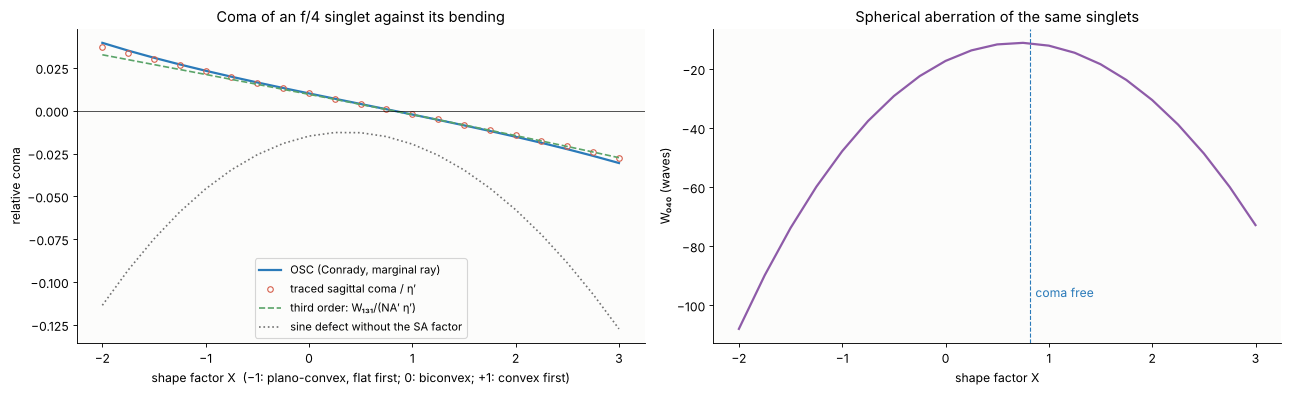

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
ax[0].plot(Xs, osc_X, "-", color=BLUE, lw=2, label="OSC (Conrady, marginal ray)")
ax[0].plot(Xs, coma_X, "o", color=RED, ms=5, mfc="none", label="traced sagittal coma / η′")
ax[0].plot(Xs, w131_X, "--", color=GREEN, label="third order: W₁₃₁/(NA′ η′)")
ax[0].plot(Xs, sine_X, ":", color=GREY, label="sine defect without the SA factor")
ax[0].axhline(0, color="k", lw=0.6)
ax[0].set_xlabel("shape factor X  (−1: plano-convex, flat first; 0: biconvex; +1: convex first)")
ax[0].set_ylabel("relative coma")
ax[0].set_title("Coma of an f/4 singlet against its bending")
ax[0].legend(fontsize=10)
ax[1].plot(Xs, w040_X, color=PURPLE, lw=2)
ax[1].axvline(X0, color=BLUE, lw=1, ls="--")
ax[1].text(X0 + 0.05, w040_X.min()*0.9, "coma free", color=BLUE)
ax[1].set_xlabel("shape factor X")
ax[1].set_ylabel("W₀₄₀ (waves)")
ax[1].set_title("Spherical aberration of the same singlets")
plt.show()

OSC and the traced coma agree within $10^{-3}$, for OSC up to 0.04 (the difference is
higher order coma, which the marginal ray alone cannot see), and the
third order coma is the tangent of both at small apertures. The
coma-free singlet is bent close to the shape of least spherical
aberration, which is why a single lens "the right way round" (convex
side to the parallel light, notebook 19) is good for both. The plain
sine defect, without Conrady's factor for the spherical aberration, is
far from zero everywhere: a lens with 12 waves of spherical aberration
need not obey $\sin U'/\sin U = \text{const}$ to be free of coma.

### Telescopes and a lithography lens

In [9]:
D_t, f1_t, F_t, b_t = 1000.0, 3000.0, 8000.0, 300.0      # the 1 m f/8 telescopes of notebook 97
systems = {"paraboloid f/0.5": parab,
           "Newtonian 200 mm f/4": tl.newtonian(200.0, 4.0),
           "classical Cassegrain 1 m f/8": tl.two_mirror_telescope(D_t, f1_t, F_t, b_t, "classical", wavelength=lam),
           "Ritchey-Chretien 1 m f/8": tl.two_mirror_telescope(D_t, f1_t, F_t, b_t, "rc", wavelength=lam),
           "singlet X = -1 (flat side first)": bent_singlet(-1.0),
           "singlet X = {:.2f} (coma free)".format(X0): bent_singlet(X0),
           "Caldwell KrF lens": caldwell}
osc_curves = {}
for name, S in systems.items():
    sc = S.sine_condition(N=30)
    osc_curves[name] = sc
    print("{:34s} NA' = {:.3f}: OSC at the rim {:+.2e}, largest |OSC| {:.2e}"
          .format(name, S.paraxial().na, sc.osc[-1], np.max(np.abs(sc.osc))))

paraboloid f/0.5                   NA' = 1.000: OSC at the rim +2.50e-01, largest |OSC| 2.50e-01
Newtonian 200 mm f/4               NA' = 0.125: OSC at the rim +3.91e-03, largest |OSC| 3.91e-03
classical Cassegrain 1 m f/8       NA' = 0.062: OSC at the rim +9.77e-04, largest |OSC| 9.77e-04


Ritchey-Chretien 1 m f/8           NA' = 0.062: OSC at the rim +5.53e-06, largest |OSC| 5.53e-06
singlet X = -1 (flat side first)   NA' = 0.125: OSC at the rim +2.33e-02, largest |OSC| 2.33e-02
singlet X = 0.82 (coma free)       NA' = 0.125: OSC at the rim +2.78e-06, largest |OSC| 2.65e-05
Caldwell KrF lens                  NA' = 0.536: OSC at the rim -2.57e-05, largest |OSC| 3.59e-05


The classical Cassegrain has the OSC of a paraboloid of its *system*
focal ratio ($\tan^2(U'/2)$ at f/8, $10^{-3}$): the secondary does not
change the coma, as notebook 97 found from the Seidel sums. The
Ritchey–Chrétien removes it to $10^{-5}$ (its conics are chosen to cancel
third order coma; what remains is fifth order). Caldwell's lens has
$|\mathrm{OSC}| < 4\times 10^{-5}$ at NA 0.54. Lithography lenses must be
aplanatic: at 11.7 mm image height an OSC of $10^{-4}$ would already mean
a comatic flare of 1.2 µm, five times the line width.

### The wave picture: Abbe's grating and the isoplanatic patch

Abbe did not derive the sine condition from rays but from gratings. A
grating of period $d$ in the object diffracts the orders
$n\sin U_k = k\lambda/d$. Its image should be a grating of period
$|m| d$, which needs the orders at $n'\sin U'_k = k\lambda/(|m|d)$ in
image space, for *every* order $k$: the sine condition again, now as the
statement that the lens maps the angular spectrum of the object linearly
onto that of the image. We send the orders of a grating through the
ellipsoid and through Caldwell's lens and compute the period that each
pair of orders $\pm k$ would write in the image:

In [10]:
def order_periods(S, d, k_max):
    """Image space period k lambda/(n' sin U'_k) written by the orders +-k of an axial grating of period d."""
    n0, n1 = S.n[0], abs(S.n[-1])
    k = np.arange(1, k_max + 1)
    sU = k*S.wavelength/(n0*d)
    k = k[sU < 1]
    sU = sU[sU < 1]
    P = np.tile([0.0, 0.0, -S.object_distance], (len(sU), 1))
    dirs = np.column_stack([0*sU, sU, np.sqrt(1 - sU**2)])
    B = S.trace(rt.Rays(P, dirs, np.zeros(len(sU))), clip=False)
    return k, sU, k*S.wavelength/(n1*np.abs(B.directions[-1][:, 1]))


d_ell = 10*lam/0.2                    # 10 orders inside the object space NA 0.2 of the ellipsoid
k_e, sU_e, dk_e = order_periods(ell, d_ell, 10)
na_c = na_obj
d_cal = caldwell.wavelength/(na_c/12)  # 12 orders inside the NA of Caldwell's lens
k_c, sU_c, dk_c = order_periods(caldwell, d_cal, 12)
m_e, m_c = abs(ell.paraxial().magnification), abs(pc.magnification)
print("ellipsoid: image period of the orders / (|m| d) from {:.4f} (k = 1) to {:.4f} (k = {})"
      .format(dk_e[0]/(m_e*d_ell), dk_e[-1]/(m_e*d_ell), k_e[-1]))
print("Caldwell:  from {:.6f} to {:.6f} (k = {})".format(dk_c[0]/(m_c*d_cal), dk_c[-1]/(m_c*d_cal), k_c[-1]))

ellipsoid: image period of the orders / (|m| d) from 1.0015 (k = 1) to 1.1515 (k = 10)
Caldwell:  from 0.999999 to 0.999970 (k = 12)


In the lithography lens every pair of orders writes the same period to
$3\times 10^{-5}$: the image of a grating is a grating. In the ellipsoid
the high orders write periods up to 15 % too long. In Abbe's argument
the harmonics of the image then do not fit its fundamental, so the
image of a grating cannot be a grating of one period: it changes shape
from one line to the next. That is coma seen in the frequency domain,
and it is why the sine condition is the condition
of **isoplanatism**: in an aplanatic lens the PSF has the same shape over
a small field patch, so that the image is a convolution there. The PSF
of the two 1 m f/8 telescopes at the centre, at 0.03° and at 0.06° shows it
(the sagittal coma of the classical Cassegrain is OSC·η′ = 8 µm at
0.06°, 1.5 Airy radii):

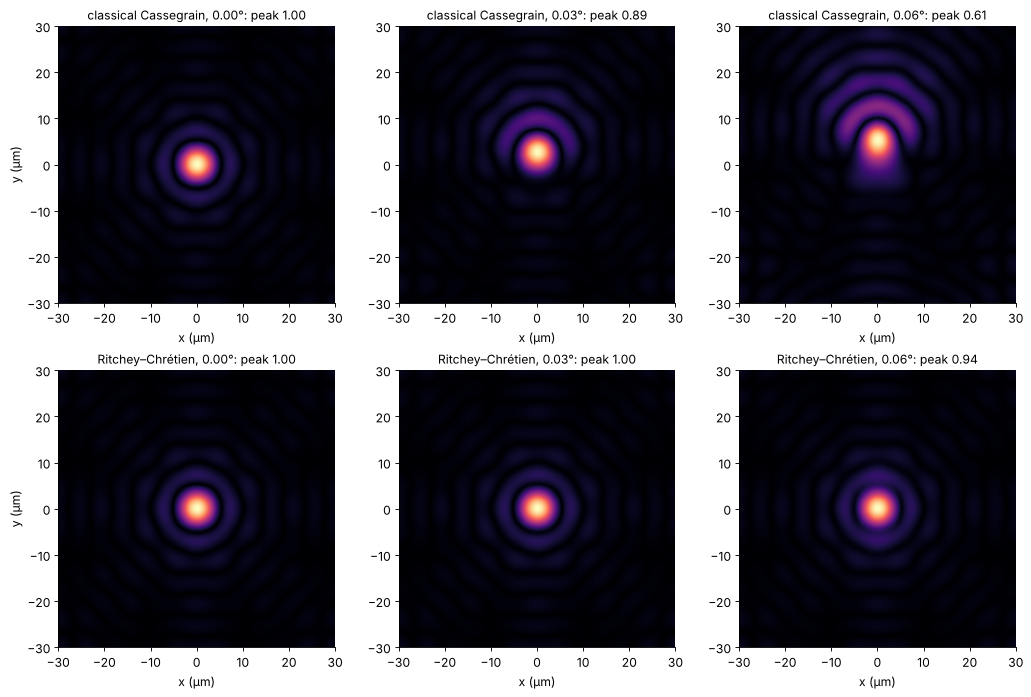

classical Cassegrain Z8 (waves) at 0.02...0.1 deg: [0.103 0.206 0.31  0.413 0.516]; NA' OSC eta'/(3 lambda): [0.103 0.207 0.31  0.413 0.516]
Ritchey-Chretien     Z8 (waves) at 0.02...0.1 deg: [0.001 0.001 0.002 0.003 0.003]; NA' OSC eta'/(3 lambda): [0.001 0.001 0.002 0.002 0.003]


In [11]:
cass = systems["classical Cassegrain 1 m f/8"]
rc = systems["Ritchey-Chretien 1 m f/8"]
xg = np.linspace(-0.03, 0.03, 256)
fields_t = [0.0, np.radians(0.03), np.radians(0.06)]
fig, ax = plt.subplots(2, 3, figsize=(13, 8.6), layout="constrained")
for row, (name, S) in enumerate((("classical Cassegrain", cass), ("Ritchey–Chrétien", rc))):
    for col, fl in enumerate(fields_t):
        I = np.abs(S.psf(xg, xg, fl, N=96))**2
        ax[row, col].imshow(I**0.5, extent=[xg[0]*1e3, xg[-1]*1e3, xg[0]*1e3, xg[-1]*1e3], origin="lower",
                            cmap="magma")
        ax[row, col].set_title("{}, {:.2f}°: peak {:.2f}".format(name, np.degrees(fl), I.max()), fontsize=11)
        ax[row, col].set_xlabel("x (µm)")
    ax[row, 0].set_ylabel("y (µm)")
plt.show()

zc = {}
for name, S in (("classical Cassegrain", cass), ("Ritchey-Chretien", rc)):
    flds = np.radians([0.02, 0.04, 0.06, 0.08, 0.1])
    z8 = np.array([S.zernike(fl, n_terms=9, N=48)[7] for fl in flds])
    eta = np.array([S.paraxial(fl).image_height for fl in flds])
    sc = osc_curves["classical Cassegrain 1 m f/8" if "classical" in name else "Ritchey-Chretien 1 m f/8"]
    pred = S.paraxial().na*sc.osc[-1]*eta/3/S.wavelength
    zc[name] = (z8, pred)
    print("{:20s} Z8 (waves) at 0.02...0.1 deg: {}; NA' OSC eta'/(3 lambda): {}"
          .format(name, np.round(z8, 3), np.round(pred, 3)))

The Ritchey–Chrétien PSF stays an Airy pattern (only the peak drops a
little, from astigmatism, notebook 97); the classical Cassegrain grows
a comatic tail that is longer at twice the field. The coma Zernike $Z_8$
(the fringe $y$ coma, $(3\rho^3 - 2\rho)$ times the pupil coordinate along
the field) grows linearly with the field, and its slope is the OSC: a
wavefront $W = W_c\,\rho^3\cos\varphi$ deflects the sagittal rim rays by
$W_c/\mathrm{NA}'$, so $W_c = \mathrm{NA}'\,\mathrm{OSC}\,\eta'$ and
$Z_8 = W_c/3$, to within 1 % (the magnitude; the sign of the pupil
coordinate is that of `System.zernike()`, which differs from the
imaging pupil, see its docstring).

## 3. The aplanatic points of a sphere

A single refracting sphere of radius $R$ between the indices $n$ and $n'$
has one pair of conjugate points that it images perfectly at every
aperture: the object $O$ at the distance $R\,n'/n$ from the centre $C$
and its (virtual) image $I$ at $R\,n/n'$, on the same side. In the
triangle $C$, $O$ and the point $P$ where a ray meets the sphere, the law
of sines gives the angle of incidence, $\sin i = (n'/n)\sin U$; Snell's
law turns this into $\sin i' = \sin U$; and in the triangle $C$, $P$, $I$
the law of sines gives $\sin U' = (n'/n)\sin i' = (n'/n)\sin U$. All
refracted rays point back to $I$ (stigmatism), and

$$\frac{\sin U}{\sin U'} = \frac{n}{n'}\quad\text{for every ray}:$$

the sphere satisfies the sine condition, with the magnification
$m = n\sin U/(n'\sin U') = (n/n')^2$.

This is the front lens of most high NA microscope objectives (Amici,
about 1850): the object sits in immersion oil under a hemisphere of
glass of the same index; the hemisphere turns the cone of NA 1.19 in the
oil into one of $\sin U' = 1.19/n^2 = 0.53$ in air, and a meniscus
behind it, whose first surface is centred on the virtual image and whose second surface is again
aplanatic, divides the sine by $n$ once more. Each aplanatic surface
reduces the NA by the factor $n$ without aberrations, and the
conventional lenses behind them only need to handle the rest.

In [12]:
n_g, R_s = 1.5, 2.0


def amici_front(meniscus=True, gap=0.2, t=2.0, n=n_g, Rs=R_s, wavelength=lam, sd=0.995):
    """Aplanatic hemisphere (object in a medium of index n at R/n beyond the centre), optionally followed
    by a concentric-aplanatic meniscus. Vertex of the sphere at z = 0, centre at z = -R."""
    zI1 = -Rs - n*Rs                       # virtual image of the sphere, z relative to its vertex
    s = [rt.Surface(-Rs, gap, n_after=1.0, semi_diameter=sd*Rs, label="aplanatic sphere")]
    if meniscus:
        v1, v2 = gap, gap + t
        R1 = -(v1 - zI1)                   # concentric with the virtual image: no refraction
        R2 = (v2 - zI1)/(1 + 1/n)          # aplanatic for the virtual image seen from inside the glass
        s += [rt.Surface(R1, t, n_after=n, semi_diameter=0.95*abs(R1)),
              rt.Surface(-R2, 0.0, n_after=1.0, semi_diameter=0.95*R2, label="aplanatic meniscus")]
    S = rt.System(s, 0, wavelength, object_distance=Rs + Rs/n, object_height=1e-3, n_object=n)
    return S.at_paraxial_focus()


for name, S in (("aplanatic hemisphere", amici_front(False)), ("hemisphere + meniscus", amici_front(True))):
    p = S.paraxial()
    sc = S.sine_condition(N=30)
    print("{:22s} m = {:.4f} (n^2 = {:.4f}, n^3 = {:.4f}); object NA {:.3f} -> image NA {:.3f}; "
          "rms OPD {:.1e} waves, max |OSC| {:.1e}, Herschel defect at the rim {:+.3f}"
          .format(name, p.magnification, n_g**2, n_g**3, n_g*sc.sin_u[-1], np.abs(sc.sin_u_prime[-1]),
                  S.rms_opd(0.0, remove_tilt=False), np.max(np.abs(sc.osc)), sc.herschel_defect[-1]))
amici = amici_front(True)

aplanatic hemisphere   m = 2.2500 (n^2 = 2.2500, n^3 = 3.3750); object NA 1.188 -> image NA 0.528; rms OPD 1.6e-12 waves, max |OSC| 4.4e-16, Herschel defect at the rim +0.148
hemisphere + meniscus  m = 3.3750 (n^2 = 2.2500, n^3 = 3.3750); object NA 1.188 -> image NA 0.352; rms OPD 4.7e-12 waves, max |OSC| 6.7e-16, Herschel defect at the rim +0.202


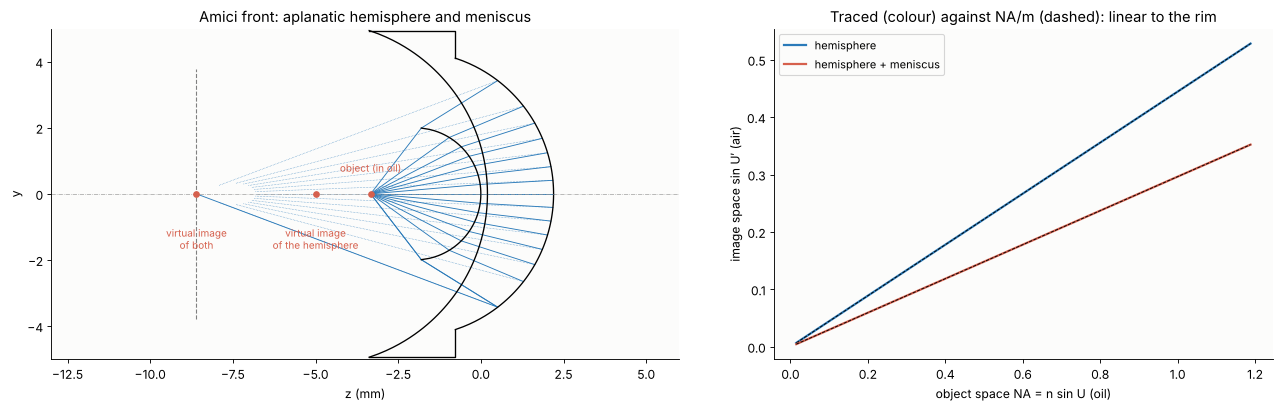

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained", width_ratios=[1.4, 1])
B = amici.trace_pupil(0.0, 0.0, np.linspace(-1, 1, 15))
zv = amici.vertex_z
z_obj = -amici.object_distance
for i in range(B.points.shape[1]):
    zz = np.concatenate([[z_obj], B.points[1:-1, i, 2]])
    yy = np.concatenate([[0.0], B.points[1:-1, i, 1]])
    ax[0].plot(zz, yy, color=BLUE, lw=0.8)
    # virtual continuation backwards to the final virtual image
    d = B.directions[-2, i]
    P = B.points[-2, i]
    tt = np.linspace(-9, 0, 2)
    ax[0].plot(P[2] + tt*d[2], P[1] + tt*d[1], color=BLUE, lw=0.5, ls=":")
amici.draw(ax[0], fields=[0.0], n_rays=1, colors=[BLUE])
z_img = zv[-1] + amici.paraxial().image_distance
for zz, lbl, yt in ((z_obj, "object (in oil)", 0.6), (-R_s - n_g*R_s, "virtual image\nof the hemisphere", -1.0),
                    (z_img, "virtual image\nof both", -1.0)):
    ax[0].plot(zz, 0, "o", color=RED, ms=5)
    ax[0].text(zz, yt, lbl, ha="center", va="top" if yt < 0 else "bottom", fontsize=9, color=RED)
ax[0].set_aspect("equal", adjustable="box")
ax[0].set_xlim(-13, 6)
ax[0].set_ylim(-5, 5)
ax[0].set_xlabel("z (mm)")
ax[0].set_title("Amici front: aplanatic hemisphere and meniscus")
for name, S, c in (("hemisphere", amici_front(False), BLUE), ("hemisphere + meniscus", amici, RED)):
    sc = S.sine_condition(N=60)
    ax[1].plot(n_g*sc.sin_u, np.abs(sc.sin_u_prime), color=c, lw=2, label=name)
    ax[1].plot(n_g*sc.sin_u, n_g*sc.sin_u/abs(S.paraxial().magnification), "--", color="k", lw=0.8)
ax[1].set_xlabel("object space NA = n sin U (oil)")
ax[1].set_ylabel("image space sin U′ (air)")
ax[1].set_title("Traced (colour) against NA/m (dashed): linear to the rim")
ax[1].legend(fontsize=10)
plt.show()

Both stages are perfect to rounding ($10^{-11}$ waves, OSC $10^{-16}$):
the sine of the image space angle is exactly the object NA divided by
$m = n^2$ and $n^3$, up to the object NA of 1.19 that the hemisphere
accepts here. But the Herschel defect is not zero: 15 % at the rim of
the hemisphere and 20 % behind the meniscus. The aplanatic points are
a pair of points with sharp neighbours in the plane, not along the
axis.

## 4. The Herschel condition

Move the object point by $\delta z$ along the axis instead. The optical
path along a ray at the angle $U$ changes by $-n\,\delta z\cos U$ in the
object space and that to the image point shifted by $\delta z'$ by
$n'\,\delta z'\cos U'$. The new image is perfect only if the sum is the
same for all rays, as it is for the axial ray:

$$n\,\delta z\,(1 - \cos U) = n'\,\delta z'\,(1 - \cos U')
\quad\Longleftrightarrow\quad
n\,\delta z\sin^2\frac{U}{2} = n'\,\delta z'\sin^2\frac{U'}{2}$$

(Herschel 1821). Otherwise the moved point sees the wavefront error

$$W(U) = n'\,\delta z'\,(\cos U' - 1) - n\,\delta z\,(\cos U - 1),$$

linear in $\delta z$, which no refocusing $\delta z'$ removes: a high order
spherical aberration. `sine_condition()` returns the Herschel defect
$\frac{\sin^2(U/2)/\sin^2(U'/2)}{u^2/u'^2} - 1$, zero for every ray if
the condition holds. We move the object of the aplanatic hemisphere and
of Caldwell's lens, trace the OPD of the moved point and compare it with
$W(U)$ for the paraxial image shift $\delta z'$ (both with the best
focus, the term in $\cos U'$, removed):

In [14]:
def shifted(S, dz):
    """Copy of a finite conjugate system with the object moved by dz along +z, image in the paraxial focus."""
    return rt.System(S.surfaces, S.stop_index, S.wavelength, object_distance=S.object_distance - dz,
                     object_height=S.max_field, n_object=S.n_object).at_paraxial_focus()


def axial_opd(S, py=np.linspace(0, 1, 41)):
    """OPD (mm) of meridional rays from the axial point, with sin U and sin U'."""
    b = S.trace_pupil(0.0, 0.0, py)
    W = S._opd(b, S.trace_pupil(0.0, 0.0, 0.0))
    return W, b.directions[0][:, 1], b.directions[-1][:, 1]


def remove_focus(W, sUp, weights=None):
    """Remove piston and the exact defocus term cos U' (least squares over the pupil area in sin U')."""
    s = np.abs(sUp)
    w = s if weights is None else weights          # ring weight ~ sin U' d(sin U') on a uniform grid in sin U'
    A = np.column_stack([np.ones_like(s), np.sqrt(1 - s**2)])
    ok = np.isfinite(W) & np.isfinite(s)
    c = np.linalg.lstsq(A[ok]*np.sqrt(w[ok])[:, None], W[ok]*np.sqrt(w[ok]), rcond=None)[0]
    return W - A @ c


def herschel_prediction(S0, dz, sU, sUp):
    n0, n1 = S0.n[0], abs(S0.n[-1])
    dzp = shifted(S0, dz).paraxial().image_distance - S0.paraxial().image_distance
    dzp = dzp + 0.0
    U, Up = np.arcsin(sU), np.arcsin(sUp)
    return n1*dzp*(np.cos(Up) - 1) - n0*dz*(np.cos(U) - 1), dzp


hemi = amici_front(False)
cases = {"aplanatic hemisphere": (hemi, 2e-3), "Caldwell lens": (caldwell, 0.5)}
herschel_res = {}
for name, (S0, dz) in cases.items():
    S1 = shifted(S0, dz)
    W1, sU, sUp = axial_opd(S1)
    W0, _, _ = axial_opd(S0)
    W_trace = W1 - W0
    W_pred, dzp = herschel_prediction(S0, dz, sU, sUp)
    r_t, r_p = remove_focus(W_trace, sUp), remove_focus(W_pred, sUp)
    herschel_res[name] = (sUp, r_t/S0.wavelength, r_p/S0.wavelength)
    print("{:20s} object moved {} mm, image {:.4f} mm (axial magnification {:.4f}): residual after refocus "
          "{:.3f} waves P-V traced, {:.3f} predicted, max difference {:.4f} waves"
          .format(name, dz, dzp, dzp/dz, np.ptp(r_t)/S0.wavelength, np.ptp(r_p)/S0.wavelength,
                  np.max(np.abs(r_t - r_p))/S0.wavelength))

aplanatic hemisphere object moved 0.002 mm, image 0.0067 mm (axial magnification 3.3725): residual after refocus 0.100 waves P-V traced, 0.099 predicted, max difference 0.0009 waves
Caldwell lens        object moved 0.5 mm, image 0.0313 mm (axial magnification 0.0625): residual after refocus 0.445 waves P-V traced, 0.445 predicted, max difference 0.0000 waves


Caldwell lens: Strehl 0.8 (rms lambda/14) for an object moved by 0.33 mm along the axis (paraxial depth of focus lambda/(2 NA^2) in the object space: 0.007 mm)


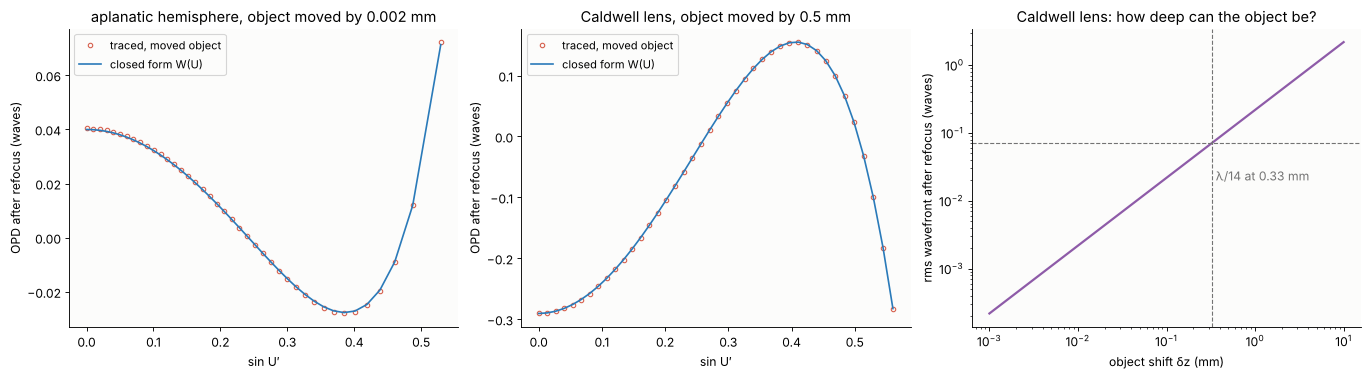

In [15]:
def herschel_rms(S0, dz, n_pupil=200):
    """rms (waves) of the Herschel wavefront of an aplanatic lens after refocus, over a uniform pupil in sin U'."""
    na_img = S0.paraxial().na
    sUp = np.linspace(0, na_img, n_pupil)
    m = S0.paraxial().magnification
    n0, n1 = S0.n[0], abs(S0.n[-1])
    sU = np.clip(np.abs(m)*n1*sUp/n0, 0, 1)          # the sine condition
    W, _ = herschel_prediction(S0, dz, sU, sUp)
    r = remove_focus(W, sUp)
    w = sUp/np.sum(sUp)
    return np.sqrt(np.sum(w*r**2) - np.sum(w*r)**2)/S0.wavelength


depths = np.geomspace(1e-3, 10, 40)
rms_cal = np.array([herschel_rms(caldwell, d) for d in depths])
dz_mar = np.interp(1/14, rms_cal, depths)
print("Caldwell lens: Strehl 0.8 (rms lambda/14) for an object moved by {:.2f} mm along the axis "
      "(paraxial depth of focus lambda/(2 NA^2) in the object space: {:.3f} mm)"
      .format(dz_mar, caldwell.wavelength/(2*na_obj**2)))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for a, (name, (sUp, r_t, r_p)) in zip(ax[:2], herschel_res.items()):
    a.plot(np.abs(sUp), r_t, "o", color=RED, ms=4, mfc="none", label="traced, moved object")
    a.plot(np.abs(sUp), r_p, "-", color=BLUE, label="closed form W(U)")
    a.set_xlabel("sin U′")
    a.set_ylabel("OPD after refocus (waves)")
    a.set_title("{}, object moved by {} mm".format(name, cases[name][1]))
    a.legend(fontsize=10)
ax[2].loglog(depths, rms_cal, color=PURPLE, lw=2)
ax[2].axhline(1/14, color=GREY, ls="--", lw=1)
ax[2].axvline(dz_mar, color=GREY, ls="--", lw=1)
ax[2].text(dz_mar*1.1, 0.02, "λ/14 at {:.2f} mm".format(dz_mar), color=GREY)
ax[2].set_xlabel("object shift δz (mm)")
ax[2].set_ylabel("rms wavefront after refocus (waves)")
ax[2].set_title("Caldwell lens: how deep can the object be?")
plt.show()

The traced wavefront of the moved point and the closed form lie on top
of each other: the residual of both lenses is the Herschel term and
nothing else. An object moved by 2 µm under the hemisphere gives a
tenth of a wave of high order spherical aberration; Caldwell's lens
tolerates a reticle that is 0.33 mm out of its plane (its object space
depth of focus is only 7 µm, but refocusing takes care of that: what
cannot be refocused is the Herschel residual). For lithography that is
plenty, a mask is flat. For a microscope that looks at a thick
specimen, it is the reason why an objective images one plane well and
the planes above and below it badly.

## 5. Why not both?

An aplanatic lens has $\sin U' = c\sin U$ with $c = n/(n'm)$ for every
ray. For Herschel, $\sin(U'/2) = c'\sin(U/2)$ for every ray. Both maps
start as $U' = cU$, but their third order terms differ,
$U' = cU\,[1 + (c^2 - 1)U^2/6]$ against $cU\,[1 + (c^2-1)U^2/24]$. They
agree only for $c = \pm 1$: $U' = \pm U$, i.e. at the magnification

$$|m| = \frac{n}{n'}.$$

For an aplanatic lens the Herschel defect follows from the magnification
alone: with $\sin U' = c\sin U$ it is $c^2\sin^2(U/2)/\sin^2(U'/2) - 1$.

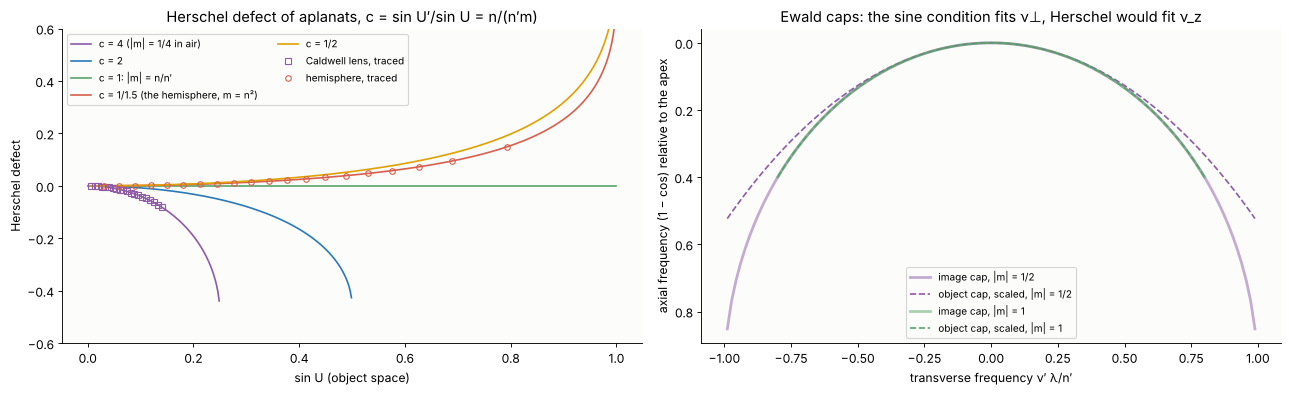

In [16]:
def herschel_of_aplanat(sU, c):
    U, Up = np.arcsin(sU), np.arcsin(np.clip(c*sU, -1, 1))
    return np.sin(U/2)**2/np.sin(Up/2)**2*c**2 - 1


fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
sU = np.linspace(1e-3, 0.999, 400)
for c, col, lbl in ((4.0, PURPLE, "c = 4 (|m| = 1/4 in air)"), (2.0, BLUE, "c = 2"), (1.0, GREEN, "c = 1: |m| = n/n′"),
                    (1/n_g, RED, "c = 1/1.5 (the hemisphere, m = n²)"), (0.5, ORANGE, "c = 1/2")):
    ok = c*sU < 1
    ax[0].plot(sU[ok], herschel_of_aplanat(sU[ok], c), color=col, lw=1.5, label=lbl)
sc_c = caldwell.sine_condition(N=20)
ax[0].plot(sc_c.sin_u, sc_c.herschel_defect, "s", color=PURPLE, ms=5, mfc="none", label="Caldwell lens, traced")
sc_h = hemi.sine_condition(N=20)
ax[0].plot(sc_h.sin_u, sc_h.herschel_defect, "o", color=RED, ms=5, mfc="none", label="hemisphere, traced")
ax[0].set_xlabel("sin U (object space)")
ax[0].set_ylabel("Herschel defect")
ax[0].set_ylim(-0.6, 0.6)
ax[0].set_title("Herschel defect of aplanats, c = sin U′/sin U = n/(n′m)")
ax[0].legend(fontsize=9, ncol=2)

# Ewald caps: the 3D coherent transfer function of object and image space
NA_o = 0.8
U = np.linspace(-np.arcsin(NA_o), np.arcsin(NA_o), 200)
for m_, col, lbl in ((-0.5, PURPLE, "|m| = 1/2"), (-1.0, GREEN, "|m| = 1")):
    c = 1/abs(m_)
    Up = np.arcsin(np.clip(c*np.sin(U), -1, 1))
    ok = np.abs(c*np.sin(U)) < 1
    # object cap mapped into the image space: transverse frequencies / m (the sine condition), axial
    # frequencies scaled by the paraxial axial magnification 1/(m^2)
    kx_o, kz_o = np.sin(U[ok])/abs(m_), (1 - np.cos(U[ok]))/m_**2
    kx_i, kz_i = np.sin(Up[ok]), 1 - np.cos(Up[ok])
    ax[1].plot(kx_i, kz_i, color=col, lw=2.5, alpha=0.5, label="image cap, " + lbl)
    ax[1].plot(kx_o, kz_o, "--", color=col, lw=1.5, label="object cap, scaled, " + lbl)
ax[1].set_xlabel("transverse frequency ν′ λ/n′")
ax[1].set_ylabel("axial frequency (1 − cos) relative to the apex")
ax[1].set_title("Ewald caps: the sine condition fits ν⊥, Herschel would fit ν_z")
ax[1].legend(fontsize=9)
ax[1].invert_yaxis()
plt.show()

The traced lenses lie on the curves of their sine ratio: Caldwell's
reduction lens on $c = 4$, the hemisphere on $c = n'/n$. Only $c = 1$,
$|m| = n/n'$, has zero Herschel defect at every aperture; demagnifying
aplanats ($c > 1$) and magnifying ones have defects of opposite sign.

The right panel is the wave optical version. The 3D coherent transfer
function of a lens in a medium of index $n$ is a cap of the Ewald sphere
of radius $n/\lambda$: the spatial frequencies
$(n\sin U, n\cos U)/\lambda$ of the plane waves that it passes. The image
of a 3D object is a scaled copy of the object if the lens maps the
object cap onto the image cap by a linear scaling of the transverse and
the axial frequencies. The sine condition fixes the transverse
scaling to $1/m$. A cap scaled by $1/m$ sideways and by $1/m_z$ in depth
($m_z = m^2 n'/n$, the paraxial axial magnification) is a sphere again
only if both scalings agree with the radii, which is the Herschel
condition, and that needs $|m| = n/n'$. At $|m| = 1/2$ the scaled cap of
the object is much flatter than the cap of the image: the 3D image is
distorted in depth, the plane waves arrive with the wrong axial
frequencies, and a point away from focus gets the spherical aberration
of section 4.

### A lens that satisfies both

At $|m| = 1$ in one medium both conditions can hold, and a symmetric
system does it: two hyperbolic plano-convex lenses (stigmatic for a
collimated beam, notebook 83), the first turned round so that it
collimates the light of the object, the second focusing it. Each half
violates the sine condition by several percent; the pair, with
$U' = -U$ for every ray, satisfies the sine and the Herschel condition at
once:

In [17]:
def hyperbolic_pair(f=50.0, a=30.0, n=1.5, gap=10.0, wavelength=lam):
    """Two plano-hyperbolic lenses (K = -n^2), curved sides out: point -> collimated -> point, m = -1."""
    R, K = (n - 1)*f, -n**2
    c = 1/R
    sag = c*a**2/(1 + np.sqrt(1 - (1 + K)*c**2*a**2))
    t = sag + 2.0
    s = [rt.Surface(R, t, n_after=n, conic=K, semi_diameter=a),
         rt.Surface(np.inf, gap/2, n_after=1.0, semi_diameter=a),
         rt.Surface(np.inf, gap/2, semi_diameter=a, label="stop"),
         rt.Surface(np.inf, t, n_after=n, semi_diameter=a),
         rt.Surface(-R, f, n_after=1.0, conic=K, semi_diameter=a)]
    return rt.System(s, 2, wavelength, object_distance=f, object_height=0.1).at_paraxial_focus()


pair = hyperbolic_pair()
sc_pair = pair.sine_condition(N=30)
half_osc = np.max(np.abs(hyperbolic_pair().sine_condition(N=30).osc))
print("hyperbolic pair: m = {:.6f}, NA = {:.3f}, rms OPD {:.1e} waves, max |OSC| {:.1e}, max |Herschel defect| {:.1e}"
      .format(pair.paraxial().magnification, pair.paraxial().na, pair.rms_opd(0.0, remove_tilt=False),
              np.max(np.abs(sc_pair.osc)), np.max(np.abs(sc_pair.herschel_defect))))
one = rt.System(pair.surfaces[3:], 0, lam).at_paraxial_focus()
print("one hyperbolic lens (object at infinity): OSC at the rim {:.3f}"
      .format(one.sine_condition(py=[1.0]).osc[0]))
for dz in (0.01, 0.1, 1.0):
    W1, sU, sUp = axial_opd(shifted(pair, dz), py=np.linspace(0, 0.98, 41))
    r = remove_focus(W1, sUp)
    print("pair: object moved by {:5.2f} mm: P-V after refocus {:.4f} waves".format(dz, (np.nanmax(r) - np.nanmin(r))/lam))

hyperbolic pair: m = -1.000000, NA = 0.600, rms OPD 3.2e-11 waves, max |OSC| 5.6e-16, max |Herschel defect| 5.1e-15
one hyperbolic lens (object at infinity): OSC at the rim 0.404
pair: object moved by  0.01 mm: P-V after refocus 0.0000 waves
pair: object moved by  0.10 mm: P-V after refocus 0.0028 waves
pair: object moved by  1.00 mm: P-V after refocus 0.2909 waves


At NA 0.6 the pair has no wavefront error, no OSC and no Herschel
defect (all at rounding level). An object moved by 0.1 mm stays a perfect
point (the residual is of second order in $\delta z$); the
hemisphere, at NA 1.19 in its object space, could not afford 2 µm.

### Remote focusing

Botcherby, Juškaitis, Booth and Wilson (2007) turned this into a
microscope that refocuses without moving the specimen or the objective.
A high NA objective in water ($n_1 = 1.33$) images the specimen into an
intermediate space through a tube lens, and a second objective in air
($n_2 = 1$) images that intermediate image into a remote space. Both
objectives are aplanatic. A small mirror in the remote space is moved in
depth, and since the magnification between specimen and remote space is
chosen as $n_1/n_2$, the sine *and* the Herschel condition hold between
them: every plane of the specimen is imaged without aberrations onto the
mirror. Compare the residual of a depth scan $\delta z$ in the specimen
for an NA 1.0 water objective refocused three ways: in a conventional
microscope by moving the camera behind the 40× tube lens, by remote
focusing at the wrong magnification 1, and at $n_1/n_2$:

camera behind a 40× tube lens (M = 40)   Strehl > 0.8 up to 6.5 µm
remote focusing at M = 1                 Strehl > 0.8 up to 2.5 µm
remote focusing at M = n₁/n₂ = 1.333     Strehl > 0.8 up to beyond 50 µm


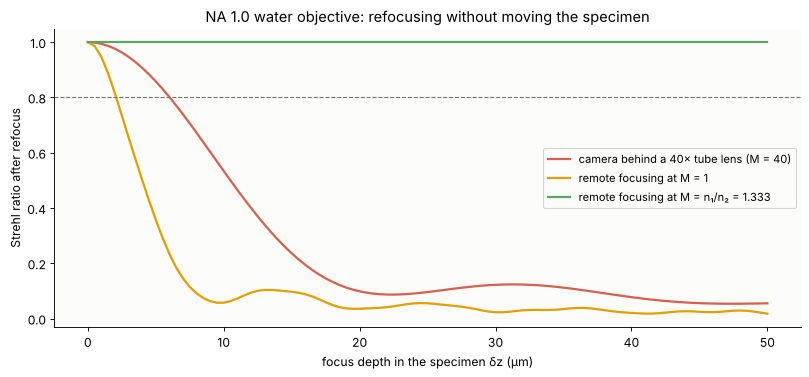

In [18]:
def refocus_strehl(dz, NA, n1, n2, M, wavelength=lam, n_pupil=400):
    """Strehl ratio of an aplanatic system of lateral magnification M from a medium n1 into n2 for an
    object point moved by dz (mm), refocused in the image space, uniform pupil in sin U."""
    sU = np.linspace(0, NA/n1, n_pupil)
    sUp = n1*sU/(n2*M)
    dzp = dz*M**2*n2/n1
    W = n2*dzp*(np.sqrt(1 - sUp**2) - 1) - n1*dz*(np.sqrt(1 - sU**2) - 1)
    r = remove_focus(W, sUp)
    w = sU/np.sum(sU)
    return np.abs(np.sum(w*np.exp(2j*np.pi*r/wavelength)))**2


NA_w, n_w = 1.0, 1.333
dzs = np.linspace(0, 0.05, 101)                    # up to 50 µm
cases_rf = {"camera behind a 40× tube lens (M = 40)": 40.0,
            "remote focusing at M = 1": 1.0,
            "remote focusing at M = n₁/n₂ = 1.333": n_w}
strehl_rf = {k: np.array([refocus_strehl(d, NA_w, n_w, 1.0, M) for d in dzs]) for k, M in cases_rf.items()}
for k, s in strehl_rf.items():
    i = np.argmax(s < 0.8) if np.any(s < 0.8) else None
    print("{:40s} Strehl > 0.8 up to {}".format(k, "{:.1f} µm".format(dzs[i]*1e3) if i else "beyond 50 µm"))

fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
for (k, s), col in zip(strehl_rf.items(), (RED, ORANGE, GREEN)):
    ax.plot(dzs*1e3, s, color=col, lw=2, label=k)
ax.axhline(0.8, color=GREY, ls="--", lw=1)
ax.set_xlabel("focus depth in the specimen δz (µm)")
ax.set_ylabel("Strehl ratio after refocus")
ax.set_title("NA 1.0 water objective: refocusing without moving the specimen")
ax.legend(fontsize=10)
plt.show()

Moving the camera refocuses by only a few micrometres before the
Herschel term destroys the focus; the image space of a 40× objective has
a tiny NA, its wavefront is a parabola, and the specimen space wavefront
at NA 1.0 is not. Remote focusing at the wrong magnification is no
better. At $M = n_1/n_2$ the two caps of section 5 coincide and the
focus stays perfect at any depth (in practice until the field of the
objectives or the working distance runs out). The same reasoning tells
why an oil objective focused deep into water loses its focus: the
index step breaks the Herschel condition of the system.

## 6. Phase space: the sine condition from Liouville

Notebook 83 showed that every lossless system maps phase space
symplectically. In 2D, a ray at the height $x$ with the direction
$p = n\sin\theta$ goes to $(x', p')$, and the Jacobian

$$J = \begin{pmatrix}\partial x'/\partial x & \partial x'/\partial p\\
\partial p'/\partial x & \partial p'/\partial p\end{pmatrix}$$

has $\det J = 1$. Take a lens with an object at infinity, from its
entrance plane to its focal plane, and the rays parallel to the axis
($p = 0$). If the lens is stigmatic on the axis, all of them go to
$x' = 0$, so $\partial x'/\partial x = 0$ and Liouville leaves

$$\frac{\partial x'}{\partial p} = -\frac{1}{\partial p'/\partial x}.$$

$\partial x'/\partial p$ is the image height per field angle *for the ray
through the height $x$*: a lens without coma needs it to be the same for
all $x$. Then $\partial p'/\partial x$ is a constant, $p' = -x/f$:
$n'\sin U' = -h/f$, the sine condition. Liouville plus stigmatism plus
isoplanatism *is* the sine condition, and the tangential coma of every
ray is $f^{-1}\,\partial x'/\partial p - 1$. The ideal lens of lens
design programs maps $x' = f\tan\theta$ for every ray, so it is free of
coma at every height, but then $\partial p'/\partial x = -\cos^3U'/f$
and $\det J = \cos^3U' \ne 1$: it buys isoplanatism by breaking
Liouville (notebook 83, section 3). A real stigmatic lens that is not
aplanatic keeps $\det J = 1$ and pays with coma:

In [19]:
F6 = 50.0


def hyperbolic_lens(a, f=F6, n=1.5):
    """Plano-convex lens, flat side to the light, hyperbolic back (K = -n^2): stigmatic on axis."""
    R, K = -(n - 1)*f, -n**2
    c = 1/R
    sag = c*a**2/(1 + np.sqrt(1 - (1 + K)*c**2*a**2))
    return rt.System([rt.Surface(np.inf, abs(sag) + 2.0, n_after=n, semi_diameter=a),
                      rt.Surface(R, f, n_after=1.0, conic=K)], 0, lam)


lenses6 = {"ideal lens": rt.System([rt.IdealLens(F6, F6, semi_diameter=200.0)], 0, lam),
           "hyperbolic plano-convex": hyperbolic_lens(55.0),
           "paraboloid": tl.newtonian(2*55.0, F6/(2*55.0))}
h6 = np.linspace(1.0, 50.0, 25)
jac6 = {}
for name, S in lenses6.items():
    z_in = -1.0 if name != "paraboloid" else -1.0
    mp = lambda X, S=S, z_in=z_in: il.system_phase_map(S, np.column_stack([X[:, 0], 0*X[:, 0], X[:, 1], 0*X[:, 0]]),
                                                       z_in=z_in)[:, [0, 2]]
    J = il.phase_space_jacobian(mp, np.column_stack([h6, 0*h6]), h=1e-6)
    f_eff = 1/abs(S.paraxial().efl**-1)
    # tangential coma traced: chief ray offset of a ray at the height h at a small field angle
    th = 1e-6
    P = np.column_stack([0*h6, h6, np.full_like(h6, -1.0)])
    d = np.tile([0.0, np.sin(th), np.cos(th)], (len(h6), 1))
    B = S.trace(rt.Rays(P, d, np.zeros(len(h6))), clip=False)
    Q, e = S.to_image_frame(B.points[-1], B.directions[-1])
    Bc = S.trace(rt.Rays(np.array([[0.0, 0.0, -1.0]]), d[:1], np.zeros(1)), clip=False)
    Qc, _ = S.to_image_frame(Bc.points[-1], Bc.directions[-1])
    tang = Q[:, 1]/(f_eff*np.sin(th))
    jac6[name] = (J, f_eff, tang)
    print("{:24s} f = {:.2f}: max |dx'/dx| = {:.1e}, det J from {:.4f} to {:.4f}, "
          "f^-1 dx'/dp - 1 at h = 50 mm: {:+.4f} (ray at 1e-6 rad: {:+.4f})"
          .format(name, f_eff, np.nanmax(np.abs(J[:, 0, 0])), np.linalg.det(J)[0], np.linalg.det(J)[-1],
                  abs(J[-1, 0, 1])/f_eff - 1, abs(tang[-1]) - 1))

# paraboloid: h = 2 f tan(U'/2), p' = -sin U', so dx'/dp = f/(cos^2(U'/2) cos U') (closed form)
Up6 = 2*np.arctan(h6/(2*F6))
J_par = jac6["paraboloid"][0]
print("paraboloid: max |f^-1 dx'/dp - 1/(cos^2(U'/2) cos U')| = {:.1e}"
      .format(np.max(np.abs(np.abs(J_par[:, 0, 1])/F6 - 1/(np.cos(Up6/2)**2*np.cos(Up6))))))
for name in ("hyperbolic plano-convex", "paraboloid"):
    S = lenses6[name]
    J = jac6[name][0]
    sc = S.sine_condition(py=h6[:3]/S.paraxial().ep_radius)
    print("{:24s} tangential coma / OSC at h = {} mm: {}".format(
        name, h6[:3], np.round((np.abs(J[:3, 0, 1])/F6 - 1)/sc.osc, 3)))

ideal lens               f = 50.00: max |dx'/dx| = 3.6e-09, det J from 0.9994 to 0.3536, f^-1 dx'/dp - 1 at h = 50 mm: +0.0000 (ray at 1e-6 rad: +0.0000)
hyperbolic plano-convex  f = 50.00: max |dx'/dx| = 4.6e-08, det J from 1.0000 to 1.0000, f^-1 dx'/dp - 1 at h = 50 mm: +4.4202 (ray at 1e-6 rad: +4.4202)
paraboloid               f = 50.00: max |dx'/dx| = 2.1e-08, det J from 1.0000 to 1.0000, f^-1 dx'/dp - 1 at h = 50 mm: +1.0833 (ray at 1e-6 rad: +1.0833)
paraboloid: max |f^-1 dx'/dp - 1/(cos^2(U'/2) cos U')| = 2.2e-10
hyperbolic plano-convex  tangential coma / OSC at h = [1.         3.04166667 5.08333333] mm: [3.001 3.013 3.036]
paraboloid               tangential coma / OSC at h = [1.         3.04166667 5.08333333] mm: [3.    3.004 3.01 ]


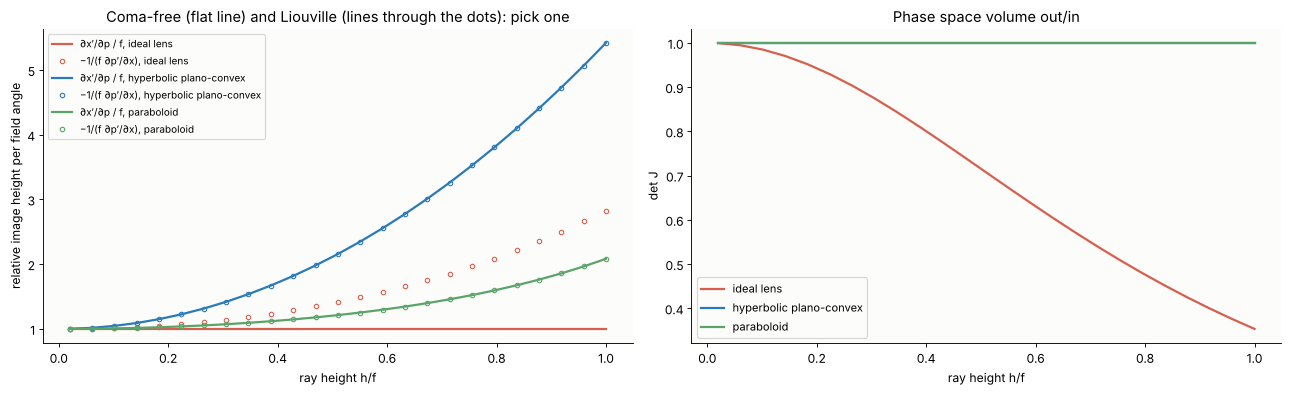

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
for (name, (J, f_eff, tang)), col in zip(jac6.items(), (RED, BLUE, GREEN)):
    ax[0].plot(h6/F6, np.abs(J[:, 0, 1])/f_eff, "-", color=col, lw=2, label="∂x′/∂p / f, " + name)
    ax[0].plot(h6/F6, 1/np.abs(J[:, 1, 0]*f_eff), "o", color=col, ms=4, mfc="none",
               label="−1/(f ∂p′/∂x), " + name)
    ax[1].plot(h6/F6, np.linalg.det(J), color=col, lw=2, label=name)
ax[0].set_xlabel("ray height h/f")
ax[0].set_ylabel("relative image height per field angle")
ax[0].set_title("Coma-free (flat line) and Liouville (lines through the dots): pick one")
ax[0].legend(fontsize=9, ncol=1)
ax[1].set_xlabel("ray height h/f")
ax[1].set_ylabel("det J")
ax[1].set_title("Phase space volume out/in")
ax[1].legend(fontsize=10)
plt.show()

For the two real lenses the line and the dots coincide (Liouville,
$\det J = 1$ to the accuracy of the differences) and rise away from 1:
tangential coma, $1/(\cos^2(U'/2)\cos U') - 1$ for the paraboloid
(against $\tan^2(U'/2)$ sagittal), to rounding. Near the axis the
tangential coma is three times the sagittal OSC, the 3:1 of third order
coma. The hyperbolic lens, which bends all its rays at the back
surface, has far more coma than the paraboloid. Only the ideal lens has
a flat line, and its dots rise above it as $1/\cos^3U'$: no physical
stigmatic lens can be free of coma unless its $p'$ is linear in $h$.

### The apodization of a high NA focus

The sine condition also fixes the amplitude in the exit pupil. A lens
that is filled with a uniform plane wave sends the power of the annulus
$h\,dh$ in its entrance pupil into the directions $\sin U'\,d(\sin U')$
of its exit pupil. On the reference sphere, as a function of the
direction sine $\sigma = \sin U'$ (the coordinates of the Debye integral
and of `propagators.vectorial_mansuripur()`, which adds the factor
$1/\sqrt{\cos U'}$ of the plane wave expansion itself), the amplitude
is

$$A(\sigma) = \sqrt{\frac{h\,dh}{f^2\,\sigma\,d\sigma}}:\qquad
1 \ \text{(sine condition)},\qquad \frac{1}{\cos^2U'} \ \text{(ideal lens, } h = f\tan U'),\qquad
\frac{1}{\cos^2(U'/2)\sqrt{\cos U'}}\ \text{(paraboloid)}.$$

An aplanatic lens fills the pupil of direction sines uniformly; the
ideal lens and the paraboloid pile up power at the rim. We check the
paraboloid's amplitude from the density of traced rays and compute the
vectorial focus of an x-polarized beam at NA 0.95 for the three laws:

In [21]:
D_par = 4*F6*np.tan(np.arcsin(0.95)/2)            # paraboloid of focal length F6 with NA' = 0.95 at its rim
sc_par = tl.newtonian(D_par, F6/D_par).sine_condition(N=400)
hh, ss = np.abs(sc_par.height), np.abs(sc_par.sin_u_prime)
fpar = hh[0]/ss[0]
A_traced = np.sqrt(hh*np.gradient(hh, ss)/(fpar**2*ss))
Up_par = np.arcsin(ss)
A_closed = 1/(np.cos(Up_par/2)**2*np.sqrt(np.cos(Up_par)))
print("paraboloid: traced ray density against the closed form amplitude: max relative difference {:.1e} "
      "(NA' to {:.3f})".format(np.max(np.abs(A_traced/A_closed - 1)[5:-5]), ss[-1]))

L_f, N_f, NA_f = 12*lam, 256, 0.95
xf = np.linspace(-L_f/2, L_f/2, N_f, endpoint=False)
KX, KY = freq_grid(xf, xf, wavenumbers=True, normal_order=True)
sig = np.hypot(KX, KY)/k0
cosU = np.sqrt(np.clip(1 - sig**2, 1e-6, None))
laws = {"aplanatic (sine condition)": np.ones_like(sig),
        "ideal lens (tan)": 1/cosU**2,
        "paraboloid": 1/(np.cos(np.arcsin(np.clip(sig, 0, 1))/2)**2*np.sqrt(cosU))}
foci = {}
for name, A in laws.items():
    P = np.where(sig < NA_f, A, 0.0)
    P = P/np.sqrt(np.sum(np.abs(P)**2))             # the same power for all three
    field = np.stack([inv_FT(P), inv_FT(0*P)], -1)
    E = prop.vectorial_mansuripur(field, xf, xf, 0.0, lam)[0]
    I = np.sum(np.abs(E)**2, -1)
    foci[name] = (E, I)
I_ref = foci["aplanatic (sine condition)"][1].max()


def fwhm(xx, prof):
    prof = prof/prof.max()
    c = len(prof)//2
    r = c + np.argmax(prof[c:] < 0.5)
    x1 = np.interp(0.5, [prof[r], prof[r - 1]], [xx[r], xx[r - 1]])
    return 2*x1


for name, (E, I) in foci.items():
    c = N_f//2
    fx, fy = fwhm(xf, I[c, :]), fwhm(xf, I[:, c])
    ez = np.sum(np.abs(E[:, :, 2])**2)/np.sum(np.abs(E)**2)
    print("{:28s} peak {:.3f}, FWHM x {:.3f} lambda, y {:.3f} lambda, power in E_z {:.1%}"
          .format(name, I.max()/I_ref, fx/lam, fy/lam, ez))

paraboloid: traced ray density against the closed form amplitude: max relative difference 1.3e-05 (NA' to 0.950)
aplanatic (sine condition)   peak 1.000, FWHM x 0.731 lambda, y 0.505 lambda, power in E_z 26.2%
ideal lens (tan)             peak 0.701, FWHM x 0.747 lambda, y 0.424 lambda, power in E_z 39.0%
paraboloid                   peak 0.947, FWHM x 0.731 lambda, y 0.465 lambda, power in E_z 32.9%


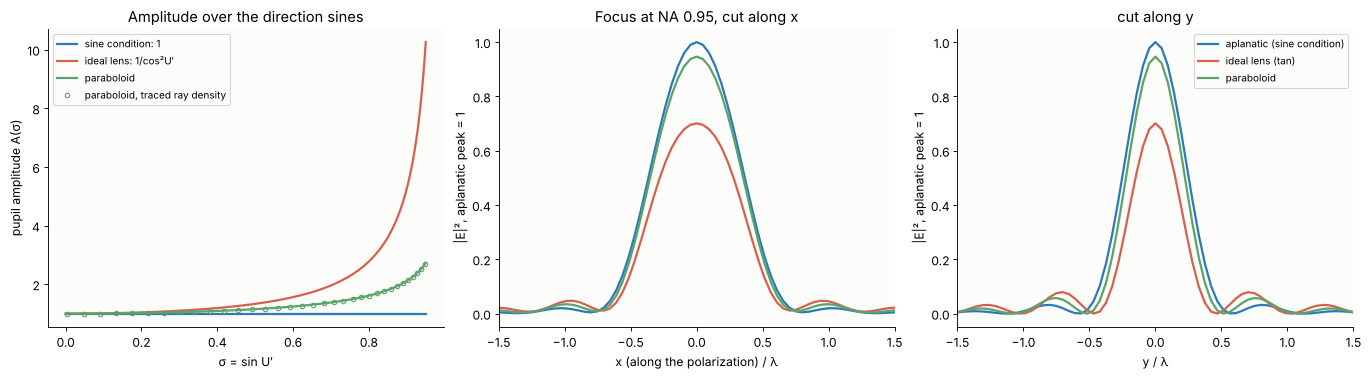

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ss_plot = np.linspace(0, 0.95, 300)
Upp = np.arcsin(ss_plot)
ax[0].plot(ss_plot, np.ones_like(ss_plot), color=BLUE, lw=2, label="sine condition: 1")
ax[0].plot(ss_plot, 1/np.cos(Upp)**2, color=RED, lw=2, label="ideal lens: 1/cos²U′")
ax[0].plot(ss_plot, 1/(np.cos(Upp/2)**2*np.sqrt(np.cos(Upp))), color=GREEN, lw=2, label="paraboloid")
ax[0].plot(ss[::12], A_traced[::12], "o", color=GREEN, ms=4, mfc="none", label="paraboloid, traced ray density")
ax[0].set_xlabel("σ = sin U′")
ax[0].set_ylabel("pupil amplitude A(σ)")
ax[0].set_title("Amplitude over the direction sines")
ax[0].legend(fontsize=9)
c = N_f//2
for (name, (E, I)), col in zip(foci.items(), (BLUE, RED, GREEN)):
    ax[1].plot(xf/lam, I[c, :]/I_ref, color=col, lw=2, label=name)
    ax[2].plot(xf/lam, I[:, c]/I_ref, color=col, lw=2, label=name)
for a, t in ((ax[1], "x (along the polarization)"), (ax[2], "y")):
    a.set_xlim(-1.5, 1.5)
    a.set_xlabel(t + " / λ")
    a.set_ylabel("|E|², aplanatic peak = 1")
ax[1].set_title("Focus at NA 0.95, cut along x")
ax[2].set_title("cut along y")
ax[2].legend(fontsize=9)
plt.show()

The ray density of the traced paraboloid reproduces the closed form. At
NA 0.95 the three foci differ visibly: the rim heavy pupils of the ideal
lens and the paraboloid put more of the power into the steep plane
waves, which narrows the central lobe across the polarization ($y$, from
0.51 λ to 0.42 λ for the ideal lens) but not along it ($x$, where the
longitudinal field grows from 26 % to 39 % of the power) and lowers the
peak by 30 %. Computing a
high NA focus with the pupil of an ideal lens is therefore wrong twice:
the lens does not exist (Liouville), and its pupil has the wrong
amplitude. `vectorial_mansuripur()`, `System.vectorial_focus()` and the
lithography imaging of notebooks 31–38 all assume the aplanatic
pupil.

## Summary

- **Lagrange = Helmholtz invariant:** $H = n(\bar u y - u\bar y)$ is the
  symplectic product of two paraxial rays, conserved behind all 42
  surfaces of Caldwell's lens to $10^{-15}$ (`System.lagrange_invariants()`);
  field × NA is 6.27 mm on both sides, and $\pi^2H^2/\lambda^2 = 6\times
  10^9$ modes. For waves it is the rms size of the Wigner function,
  $M^2\lambda/4\pi$: conserved by ABCD systems, raised from 1 to 1.76 by
  three waves of spherical aberration.
- **Sine condition:** Conrady's OSC (`System.sine_condition()`) is the
  sagittal coma per image height: $\tan^2(U'/2)$ for a paraboloid and the
  focal radius ratio for an ellipsoid (to rounding), within $10^{-3}$ of
  the traced coma over a bending series of singlets (coma free at
  $X = 0.82$, next to minimum spherical aberration), $10^{-3}$ for a
  classical Cassegrain, $5\times 10^{-6}$ for a Ritchey–Chrétien and
  $4\times 10^{-5}$ for Caldwell's lens. In wave terms: the coma Zernike
  is $Z_8 = \mathrm{NA}'\,\mathrm{OSC}\,\eta'/3$ (1 %), the PSF of an
  aplanat keeps its shape over a small field, and the orders of a grating
  write one period in the image ($3\times 10^{-5}$ in Caldwell's lens,
  not so in an ellipsoid).
- **Aplanatic sphere:** the points at $Rn'/n$ and $Rn/n'$ from the centre
  are imaged perfectly at any aperture, $m = (n/n')^2$; a hemisphere and
  a meniscus reduce NA 1.19 in oil by $n^3$ without aberrations.
- **Herschel condition:** an object moved in depth gets the wavefront
  $n'\delta z'(\cos U' - 1) - n\delta z(\cos U - 1)$, confirmed by tracing
  the hemisphere and Caldwell's lens; Caldwell's lens tolerates
  0.33 mm of reticle height.
- **Not both:** for an aplanat the Herschel defect depends on $m$ alone
  and vanishes only for $|m| = n/n'$; in wave terms the Ewald caps of the
  3D transfer function fit transversally (sine) but not axially. A
  symmetric pair of hyperbolic lenses satisfies both; remote focusing at
  $M = n_1/n_2$ refocuses an NA 1.0 water objective over any depth, a
  camera behind the tube lens over a few micrometres.
- **Phase space:** for a stigmatic lens Liouville makes
  $\partial x'/\partial p = -1/(\partial p'/\partial x)$, so coma-free
  means $p' \propto h$: the sine condition. The ideal lens is coma-free
  with $\det J = \cos^3U'$. The mapping law also sets the pupil
  amplitude: uniform in the direction sines for an aplanat,
  $1/\cos^2U'$ for the ideal lens, and the high NA foci differ.

## References

- E. Abbe, "Beiträge zur Theorie des Mikroskops und der mikroskopischen
  Wahrnehmung", Archiv für mikroskopische Anatomie 9, 413–468 (1873).
- J. F. W. Herschel, "On the aberrations of compound lenses and
  object-glasses", Phil. Trans. R. Soc. Lond. 111, 222–267 (1821).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge
  University Press (1999), sections 4.4–4.6 (sine and Herschel
  conditions, aplanatic points of a sphere).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986),
  chapters 6 and 9 (Lagrange invariant, OSC, isoplanatism).
- A. E. Conrady, *Applied Optics and Optical Design*, Part One, Oxford
  University Press (1929), the offence against the sine condition.
- H. H. Hopkins, "The Airy disc formula for systems of high relative
  aperture", Proc. Phys. Soc. 55, 116–128 (1943).
- B. Richards and E. Wolf, "Electromagnetic diffraction in optical
  systems II", Proc. R. Soc. Lond. A 253, 358–379 (1959).
- E. J. Botcherby, R. Juškaitis, M. J. Booth and T. Wilson, "An optical
  technique for remote focusing in microscopy", Opt. Commun. 281,
  880–887 (2008); and "Aberration-free optical refocusing in high
  numerical aperture microscopy", Opt. Lett. 32, 2007–2009 (2007).
- C. J. R. Sheppard and M. Gu, "Imaging by a high aperture optical
  system", J. Mod. Opt. 40, 1631–1651 (1993) (3D transfer functions and
  the sine and Herschel conditions).
- M. J. Bastiaans, "Wigner distribution function and its application to
  first-order optics", J. Opt. Soc. Am. 69, 1710–1716 (1979).
- A. E. Siegman, "New developments in laser resonators", Proc. SPIE 1224,
  2–14 (1990) (beam quality $M^2$ from second moments).

In [23]:
print("notebook run time {:.0f} s".format(time.time() - t_start))

notebook run time 6 s
